# Table 1: RMST multi-horizon sensitivity analysis

This notebook estimates **restricted mean survival time (RMST)** from
Kaplan–Meier survival curves using the full censored asset sample


In [1]:
# ---
# Imports
# ---

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from lifelines import KaplanMeierFitter


In [2]:
# ---
# Load data
# ---
df = pd.read_excel(
    "data/combined_dataset.xlsx",
    sheet_name="Dataset",
    )

In [3]:
# ---
# Configuration
# ---

technology_col = "Technology"
lifespan_col = "Lifespan"
event_col = "Event"
capacity_col = "Capacity (MW)"

# Multi-horizon sensitivity scan.
RMST_HORIZONS = [
    10,
    20,
    30,
    40,
    50,
]

# Smooth curve resolution used only for plotting RMST(tau).
TAU_STEP = 1.0

# Do not extrapolate beyond a technology's observed follow-up.
REQUIRE_OBSERVED_SUPPORT = True

OUTPUT_FIGURE_DIR = Path(
    "figures/si"
)

OUTPUT_TABLE_DIR = Path(
    "tables"
)

OUTPUT_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ---
# Technology groups
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}

technology_order = [
    tech
    for group_techs in tech_groups.values()
    for tech in group_techs
]


In [4]:
# ---
# Prepare survival-analysis data
# ---

df_survival = df.copy()

df_survival[lifespan_col] = pd.to_numeric(
    df_survival[lifespan_col],
    errors="coerce",
)

df_survival[event_col] = pd.to_numeric(
    df_survival[event_col],
    errors="coerce",
)

df_survival[capacity_col] = pd.to_numeric(
    df_survival[capacity_col],
    errors="coerce",
)

df_survival = df_survival.dropna(
    subset=[
        technology_col,
        lifespan_col,
        event_col,
    ]
).copy()

df_survival = df_survival[
    (df_survival[lifespan_col] > 0)
    & (df_survival[event_col].isin([0, 1]))
    & (df_survival[technology_col] != "Solar Thermal")
    & (df_survival[technology_col].isin(technology_order))
].copy()

df_survival[event_col] = (
    df_survival[event_col]
    .astype(int)
)

print(
    f"Assets retained: {len(df_survival):,}"
)

print(
    "Technologies:",
    ", ".join(
        tech
        for tech in technology_order
        if tech in df_survival[technology_col].unique()
    ),
)


Assets retained: 96,792
Technologies: Coal, Natural Gas, Oil, Solar PV, Wind Onshore, Wind Offshore, Nuclear, Bioenergy, Geothermal, Hydropower


In [5]:
# ---
# RMST functions
# ---

def fit_km(subset):
    km = KaplanMeierFitter()

    km.fit(
        durations=subset[lifespan_col],
        event_observed=subset[event_col],
    )

    return km


def rmst_from_km(
    km,
    tau,
    max_followup,
    require_support=True,
):
    """Integrate the KM step function from 0 to tau."""

    tau = float(tau)
    max_followup = float(max_followup)

    if tau <= 0:
        return 0.0

    if (
        require_support
        and tau > max_followup
    ):
        return np.nan

    survival_function = (
        km.survival_function_
        .iloc[:, 0]
    )

    times = (
        survival_function.index
        .to_numpy(dtype=float)
    )

    survival = (
        survival_function
        .to_numpy(dtype=float)
    )

    if len(times) == 0:
        return np.nan

    # Ensure the integral begins at t = 0 with S(0) = 1.
    if times[0] > 0:
        times = np.insert(
            times,
            0,
            0.0,
        )

        survival = np.insert(
            survival,
            0,
            1.0,
        )

    area = 0.0

    for index in range(
        len(times) - 1
    ):
        interval_start = times[index]
        interval_end = min(
            times[index + 1],
            tau,
        )

        if interval_end > interval_start:
            area += (
                survival[index]
                * (
                    interval_end
                    - interval_start
                )
            )

        if times[index + 1] >= tau:
            return area

    # Complete the final interval if tau occurs after
    # the final KM time and support is allowed.
    if tau > times[-1]:
        area += (
            survival[-1]
            * (
                tau
                - times[-1]
            )
        )

    return area


def build_technology_summary(
    technology,
):
    subset = df_survival[
        df_survival[technology_col]
        == technology
    ].copy()

    if subset.empty:
        return None

    km = fit_km(
        subset
    )

    n_assets = len(
        subset
    )

    n_retired = int(
        subset[event_col].sum()
    )

    n_censored = (
        n_assets
        - n_retired
    )

    max_followup = float(
        subset[lifespan_col].max()
    )

    km_median = (
        km.median_survival_time_
    )

    if not np.isfinite(
        km_median
    ):
        km_median = np.nan

    rmst_values = {
        tau: rmst_from_km(
            km=km,
            tau=tau,
            max_followup=max_followup,
            require_support=REQUIRE_OBSERVED_SUPPORT,
        )
        for tau in RMST_HORIZONS
    }

    return {
        "technology": technology,
        "subset": subset,
        "km": km,
        "n_assets": n_assets,
        "n_retired": n_retired,
        "n_censored": n_censored,
        "max_followup": max_followup,
        "km_median": km_median,
        "rmst_values": rmst_values,
    }


In [6]:
# ---
# Calculate RMST results
# ---

rmst_results = {}

for technology in technology_order:
    result = build_technology_summary(
        technology
    )

    if result is not None:
        rmst_results[
            technology
        ] = result


# ---
# Common support horizon
# ---

common_max_followup = min(
    result["max_followup"]
    for result in rmst_results.values()
)

common_supported_horizons = [
    tau
    for tau in RMST_HORIZONS
    if tau <= common_max_followup
]

print(
    "Maximum common observed follow-up:",
    f"{common_max_followup:.1f} years",
)

print(
    "Selected horizons supported by all technologies:",
    common_supported_horizons,
)


Maximum common observed follow-up: 29.0 years
Selected horizons supported by all technologies: [10, 20]


In [7]:
# ---
# Build RMST summary table
# ---

summary_records = []

technology_to_group = {
    technology: group_name
    for group_name, group_techs
    in tech_groups.items()
    for technology in group_techs
}

for technology in technology_order:
    if technology not in rmst_results:
        continue

    result = rmst_results[
        technology
    ]

    record = {
        "Technology": technology,
        "Group": technology_to_group[
            technology
        ],
        "Assets": result[
            "n_assets"
        ],
        "Retirements": result[
            "n_retired"
        ],
        "Censored": result[
            "n_censored"
        ],
        "Maximum follow-up (years)": result[
            "max_followup"
        ],
        "KM median (years)": result[
            "km_median"
        ],
    }

    for tau in RMST_HORIZONS:
        record[
            f"RMST at {tau} y"
        ] = result[
            "rmst_values"
        ][tau]

    summary_records.append(
        record
    )

rmst_summary_table = pd.DataFrame(
    summary_records
)

numeric_columns = [
    "Maximum follow-up (years)",
    "KM median (years)",
] + [
    f"RMST at {tau} y"
    for tau in RMST_HORIZONS
]

rmst_summary_table[
    numeric_columns
] = (
    rmst_summary_table[
        numeric_columns
    ]
    .round(1)
)

display(
    rmst_summary_table
)


,Technology,Group,Assets,Retirements,Censored,Maximum follow-up (years),KM median (years),RMST at 10 y,RMST at 20 y,RMST at 30 y,RMST at 40 y,RMST at 50 y,RMST at 60 y
0,Coal,Fossil fuels,1983,635,1348,117.0,61.0,10.0,20.0,29.9,39.6,48.6,55.7
1,Natural Gas,Fossil fuels,9259,1358,7901,125.0,62.0,10.0,19.8,29.4,38.4,46.3,52.7
2,Oil,Fossil fuels,5301,1391,3910,125.0,58.0,9.9,19.5,28.5,36.7,43.9,49.5
3,Solar PV,Core transition technologies,48931,168,48763,42.0,29.0,10.0,19.9,27.5,30.2,NaN,NaN
4,Wind Onshore,Core transition technologies,17036,325,16711,55.0,36.0,10.0,19.7,28.7,34.7,38.9,NaN
5,Wind Offshore,Core transition technologies,354,8,346,29.0,24.0,10.0,19.7,NaN,NaN,NaN,NaN
6,Nuclear,Core transition technologies,645,226,419,56.0,45.0,9.8,19.0,27.5,34.9,40.2,NaN
7,Bioenergy,Other low-carbon technologies,5345,527,4818,125.0,68.0,9.9,19.3,27.7,35.4,42.8,49.7
8,Geothermal,Other low-carbon technologies,621,141,480,67.0,NaN,10.0,19.7,27.4,33.2,38.4,43.5
9,Hydropower,Other low-carbon technologies,7317,263,7054,134.0,NaN,10.0,20.0,29.9,39.9,49.7,59.6


In [8]:
# ---
# Export tables
# ---

output_excel = (
    OUTPUT_TABLE_DIR
    / "rmst_multihorizon_summary.xlsx"
)

with pd.ExcelWriter(
    output_excel,
    engine="openpyxl",
) as writer:
    rmst_summary_table.to_excel(
        writer,
        sheet_name="RMST summary",
        index=False,
    )

print(
    f"Saved table: {output_excel}"
)


Saved table: tables/rmst_multihorizon_summary.xlsx


In [9]:
# ---
# Figure style
# ---

# Minimum font size: 12 pt
FONT_BASE = 12.0
FONT_TICKS = 12.0
FONT_PANEL = 12.5
FONT_TITLE = 12.5
FONT_AXIS_LABEL = 13.5
FONT_LEGEND = 12.0
FONT_NOTE = 12.0

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.75,
        "axes.labelsize": FONT_AXIS_LABEL,
        "axes.titlesize": FONT_TITLE,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TICKS,
        "legend.fontsize": FONT_LEGEND,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)

tech_colors = {
    "Coal": "#5A5A5A",
    "Natural Gas": "#8C8C8C",
    "Oil": "#B0B0B0",
    "Solar PV": "#D9B642",
    "Wind Onshore": "#4F9AB8",
    "Wind Offshore": "#3F708F",
    "Nuclear": "#72AAA4",
    "Bioenergy": "#7BAF7B",
    "Geothermal": "#B94745",
    "Hydropower": "#6A8FBF",
}

COLOR_TEXT = "#222222"
COLOR_AXIS = "#444444"
COLOR_GRID = "#BFBFBF"
COLOR_REFERENCE = "#777777"
COLOR_BACKGROUND = "white"

LINE_WIDTH = 1.7
MARKER_SIZE = 34


In [10]:
# ---
# Prepare RMST curves for plotting
# ---

plot_tau_max = max(
    RMST_HORIZONS
)

rmst_curve_data = {}

for technology, result in rmst_results.items():
    supported_tau_max = min(
        plot_tau_max,
        result[
            "max_followup"
        ],
    )

    tau_grid = np.arange(
        1.0,
        supported_tau_max
        + TAU_STEP,
        TAU_STEP,
    )

    rmst_grid = np.array(
        [
            rmst_from_km(
                km=result["km"],
                tau=tau,
                max_followup=result[
                    "max_followup"
                ],
                require_support=REQUIRE_OBSERVED_SUPPORT,
            )
            for tau in tau_grid
        ]
    )

    rmst_curve_data[
        technology
    ] = {
        "tau": tau_grid,
        "rmst": rmst_grid,
    }


In [11]:
# ---
# Plotting helper
# ---

def plot_group_panel(
    ax,
    group_name,
    technologies,
    panel_label,
):
    # No-retirement reference: RMST(tau) = tau.
    reference_tau = np.linspace(
        0,
        plot_tau_max,
        200,
    )

    ax.plot(
        reference_tau,
        reference_tau,
        color=COLOR_REFERENCE,
        linestyle="--",
        linewidth=1.0,
        alpha=0.65,
        zorder=1,
        label="No retirement before tau",
    )

    for technology in technologies:
        if technology not in rmst_results:
            continue

        curve = rmst_curve_data[
            technology
        ]

        ax.plot(
            curve["tau"],
            curve["rmst"],
            color=tech_colors[
                technology
            ],
            linewidth=LINE_WIDTH,
            label=technology,
            zorder=3,
        )

        result = rmst_results[
            technology
        ]

        valid_tau = []
        valid_rmst = []

        for tau in RMST_HORIZONS:
            value = result[
                "rmst_values"
            ][tau]

            if np.isfinite(value):
                valid_tau.append(
                    tau
                )
                valid_rmst.append(
                    value
                )

        ax.scatter(
            valid_tau,
            valid_rmst,
            s=MARKER_SIZE,
            color=tech_colors[
                technology
            ],
            edgecolor="white",
            linewidth=0.65,
            zorder=4,
        )

    ax.set_xlim(
        0,
        plot_tau_max,
    )

    ax.set_ylim(
        0,
        plot_tau_max,
    )

    ax.set_xticks(
        RMST_HORIZONS
    )

    ax.grid(
        axis="both",
        color=COLOR_GRID,
        linewidth=0.45,
        linestyle="-",
        alpha=0.30,
        zorder=0,
    )

    ax.set_axisbelow(
        True
    )

    for spine in [
        "top",
        "right",
    ]:
        ax.spines[
            spine
        ].set_visible(
            False
        )

    ax.spines[
        "left"
    ].set_color(
        COLOR_AXIS
    )

    ax.spines[
        "bottom"
    ].set_color(
        COLOR_AXIS
    )

    ax.tick_params(
        axis="both",
        direction="out",
        length=3.2,
        width=0.75,
        pad=3,
        colors=COLOR_TEXT,
        labelsize=FONT_TICKS,
    )

    ax.text(
        -0.13,
        1.08,
        panel_label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_PANEL,
        fontweight="bold",
        color=COLOR_TEXT,
    )

    ax.set_title(
        group_name,
        loc="left",
        fontsize=FONT_TITLE,
        fontweight="bold",
        pad=10,
        color=COLOR_TEXT,
    )

    handles, labels = (
        ax.get_legend_handles_labels()
    )

    tech_handles = handles[1:]
    tech_labels = labels[1:]

    ax.legend(
        tech_handles,
        tech_labels,
        frameon=False,
        loc="upper left",
        fontsize=FONT_LEGEND,
        handlelength=1.7,
        handletextpad=0.45,
        borderaxespad=0.0,
    )


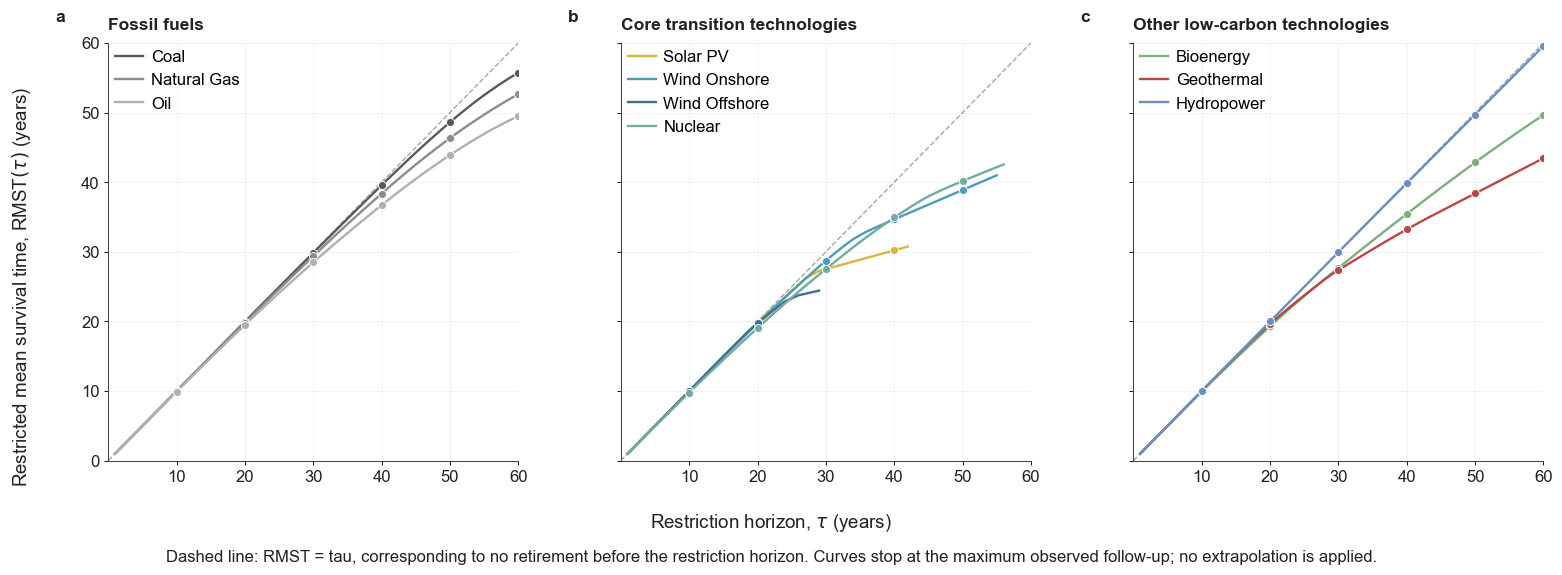

In [12]:
# ---
# RMST multi-horizon figure
# ---

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15.6, 5.8),
    sharex=True,
    sharey=True,
)

fig.patch.set_facecolor(
    COLOR_BACKGROUND
)

for ax in axes:
    ax.set_facecolor(
        COLOR_BACKGROUND
    )

group_names = list(
    tech_groups.keys()
)

for index, (
    group_name,
    technologies,
) in enumerate(
    tech_groups.items()
):
    plot_group_panel(
        ax=axes[index],
        group_name=group_name,
        technologies=technologies,
        panel_label=chr(
            97 + index
        ),
    )


# ---
# Shared labels
# ---

fig.supxlabel(
    r"Restriction horizon, $\tau$ (years)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    y=0.075,
    color=COLOR_TEXT,
)

fig.supylabel(
    r"Restricted mean survival time, RMST$(\tau)$ (years)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    x=0.012,
    color=COLOR_TEXT,
)


# ---
# Figure note
# ---

fig.text(
    0.5,
    0.020,
    (
        "Dashed line: RMST = tau, corresponding to no "
        "retirement before the restriction horizon. "
        "Curves stop at the maximum observed follow-up; "
        "no extrapolation is applied."
    ),
    ha="center",
    va="bottom",
    fontsize=FONT_NOTE,
    color=COLOR_TEXT,
)


# ---
# Layout and export
# ---

fig.subplots_adjust(
    left=0.075,
    right=0.995,
    top=0.92,
    bottom=0.20,
    wspace=0.25,
)

figure_png = (
    OUTPUT_FIGURE_DIR
    / "rmst_multihorizon.png"
)

figure_pdf = (
    OUTPUT_FIGURE_DIR
    / "rmst_multihorizon.pdf"
)

plt.savefig(
    figure_png,
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    figure_pdf,
    bbox_inches="tight",
    transparent=True,
)

plt.show()
